In [8]:
import pandas as pd
from urllib.parse import urlencode

T4_ID = "xeqp-qz8h"
API_URL = "https://data.cityofnewyork.us/resource/{}.csv"
PAGE_SIZE = 50_000

def load_crashes():
    """All SIRTA rows (same logic as src/load_data.py in the repo)."""
    pages, offset = [], 0
    while True:
        params = {"$limit": PAGE_SIZE, "$offset": offset, "$order": ":id"}
        url = API_URL.format(T4_ID) + "?" + urlencode(params)
        page = pd.read_csv(url, dtype={"zipcode": str}, low_memory=False)
        pages.append(page)
        print(f"  fetched {offset + len(page):,} rows")
        if len(page) < PAGE_SIZE:
            break
        offset += PAGE_SIZE
    return pd.concat(pages, ignore_index=True)

df_raw = load_crashes()
print("Rows, columns:", df_raw.shape)
print(df_raw.dtypes)

  fetched 13,754 rows
Rows, columns: (13754, 23)
open_data_crash_id                        float64
crash_date                                 object
crash_time                                 object
crash_police_precinct                     float64
crash_borough                              object
total_non_severe_injuries                 float64
total_severe_injuries                     float64
total_fatalities                          float64
latitude                                  float64
longitude                                 float64
on_street                                  object
cross_street                               object
address                                    object
highway_reference_marker                   object
zipcode                                    object
similar_fatalities_severe                 float64
similar_fatalities_all                    float64
community_board                           float64
council_district                          float64
b

In [9]:
# 1. First rows
display(df_raw.head(3))

# 2. Fill rate: % of non-empty values per column
print("FILL RATES (%)")
print((df_raw.notna().mean() * 100).round(1).sort_values())

# 3. Rows the contract says to drop, and duplicates
print("\nNull crash id:", df_raw["open_data_crash_id"].isna().sum())
print("Null crash date:", df_raw["crash_date"].isna().sum())
print("Duplicate crash ids (non-null):",
      df_raw["open_data_crash_id"].dropna().duplicated().sum())

# 4. Date range and year counts
dates = pd.to_datetime(df_raw["crash_date"], errors="coerce")
print("\nDate range:", dates.min(), "to", dates.max())
print(dates.dt.year.value_counts().sort_index())

# 5. Formats of the geographic columns
print("\nZIP length counts:\n", df_raw["zipcode"].str.len().value_counts(dropna=False))
print("\nBoroughs:\n", df_raw["crash_borough"].value_counts(dropna=False))

,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,...,highway_reference_marker,zipcode,similar_fatalities_severe,similar_fatalities_all,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_
0,4492364.0,2022-01-01T00:00:00.000,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,2022-01-01T00:00:00.000,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,2022-01-01T00:00:00.000,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201


FILL RATES (%)
highway_reference_marker                   7.6
address                                   18.7
bbl                                       20.3
bin                                       20.3
community_board                           28.1
council_district                          28.1
census_tract_2020_                        28.1
neighborhood_tabulation_area_nta_2020_    28.1
zipcode                                   58.7
cross_street                              59.0
on_street                                 77.9
longitude                                 79.0
latitude                                  79.0
similar_fatalities_severe                 86.6
crash_borough                             96.4
total_fatalities                          96.8
crash_police_precinct                     96.8
open_data_crash_id                        96.8
crash_time                                96.8
crash_date                                96.8
total_severe_injuries                     96.

       total_non_severe_injuries  total_severe_injuries  total_fatalities  \
count                  13310.000              13310.000         13310.000   
mean                       0.270                  1.011             0.083   
std                        0.836                  0.452             0.294   
min                        0.000                  0.000             0.000   
25%                        0.000                  1.000             0.000   
50%                        0.000                  1.000             0.000   
75%                        0.000                  1.000             0.000   
max                       19.000                  7.000             5.000   

       similar_fatalities_severe   latitude  longitude  
count                  11917.000  10868.000  10868.000  
mean                       0.095     40.731    -73.922  
std                        0.422      0.083      0.082  
min                        0.000     40.500    -74.249  
25%                  

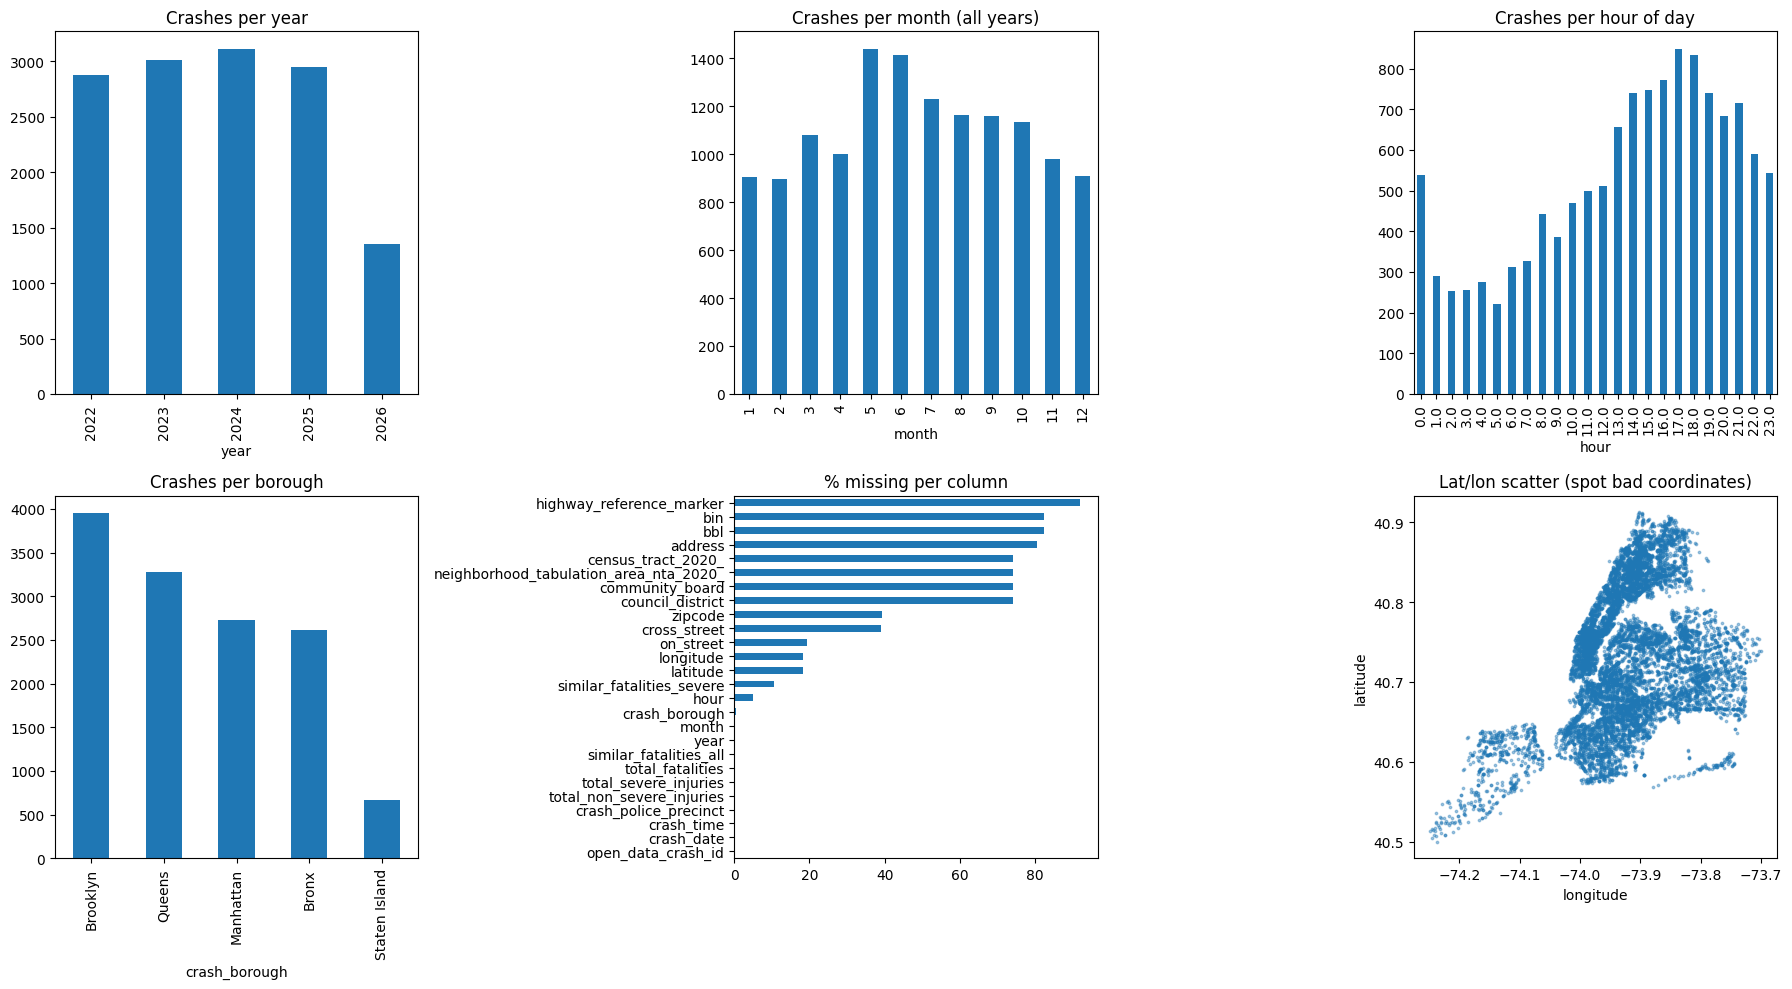

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# EDA view only: drop the 444 fully empty rows (the real cleaning comes later)
eda = df_raw.dropna(subset=["open_data_crash_id"]).copy()
eda["crash_date"] = pd.to_datetime(eda["crash_date"], errors="coerce")
eda["year"] = eda["crash_date"].dt.year
eda["month"] = eda["crash_date"].dt.month
eda["hour"] = pd.to_numeric(eda["crash_time"].str[:2], errors="coerce")

# 1. Descriptive statistics for the numeric columns that matter
num_cols = ["total_non_severe_injuries", "total_severe_injuries",
            "total_fatalities", "similar_fatalities_severe",
            "latitude", "longitude"]
print(eda[num_cols].describe().round(3))

# 2. Distribution of the count columns
for c in ["total_severe_injuries", "total_non_severe_injuries", "total_fatalities"]:
    print(f"\n{c}:\n", eda[c].value_counts().sort_index().head(12))

# 3. Check a few categorical/format issues
print("\nHighway marker sample:\n", eda["highway_reference_marker"].dropna().head(5).tolist())
print("Unique ZIPs:", eda["zipcode"].nunique())
print("Odd crash_time values:", (~eda["crash_time"].str.match(r"^\d{2}:\d{2}$", na=False)).sum())

# 4. Plots
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
eda["year"].value_counts().sort_index().plot.bar(ax=ax[0, 0], title="Crashes per year")
eda["month"].value_counts().sort_index().plot.bar(ax=ax[0, 1], title="Crashes per month (all years)")
eda["hour"].value_counts().sort_index().plot.bar(ax=ax[0, 2], title="Crashes per hour of day")
eda["crash_borough"].value_counts().plot.bar(ax=ax[1, 0], title="Crashes per borough")
(eda.isna().mean() * 100).sort_values().plot.barh(ax=ax[1, 1], title="% missing per column")
ax[1, 2].scatter(eda["longitude"], eda["latitude"], s=3, alpha=0.4)
ax[1, 2].set(title="Lat/lon scatter (spot bad coordinates)", xlabel="longitude", ylabel="latitude")
plt.tight_layout()
plt.show()

In [11]:
# What do the 656 odd crash_time values look like?
odd = eda[~eda["crash_time"].str.match(r"^\d{2}:\d{2}$", na=False)]
print(odd["crash_time"].value_counts(dropna=False).head(15))

# Is 00:00 a placeholder? Compare the exact time 00:00 with other times in hour 0
hour0 = eda[eda["hour"] == 0]["crash_time"].value_counts().head(8)
print("\nTop times within hour 0:\n", hour0)

# Also: the printed describe() output from the earlier cell (injury counts, lat/lon ranges)
print("\nMax injuries/fatalities in one crash:")
print(eda[["total_severe_injuries", "total_non_severe_injuries", "total_fatalities"]].max())

crash_time
0:00    41
1:00    11
9:00    10
7:45     9
9:30     9
8:35     7
7:00     7
8:00     7
3:00     7
8:30     6
8:50     6
6:00     6
0:48     6
0:10     6
9:50     6
Name: count, dtype: int64

Top times within hour 0:
 crash_time
00:00    186
00:15     22
00:30     21
00:20     16
00:10     15
00:05     15
00:45     12
00:55     12
Name: count, dtype: int64

Max injuries/fatalities in one crash:
total_severe_injuries         7.0
total_non_severe_injuries    19.0
total_fatalities              5.0
dtype: float64


In [12]:
import numpy as np

# NYC bounding box (rule from DATA_CONTRACT section 7)
LAT_MIN, LAT_MAX = 40.45, 40.95
LON_MIN, LON_MAX = -74.30, -73.65

def clean_crashes_basic(df_raw):
    """Pre-integration cleaning of SIRTA, following DATA_CONTRACT section 7.
    The spatial recovery of missing ZIP/borough is done in a separate step."""
    df = df_raw.copy()
    log = {"raw rows": len(df)}

    # 1. Drop rows with null crash id or date (the 444 empty rows)
    df = df.dropna(subset=["open_data_crash_id", "crash_date"])
    log["after dropping null id/date"] = len(df)

    # 2. Dedupe on crash id, keeping the first occurrence
    df["open_data_crash_id"] = df["open_data_crash_id"].astype("int64")
    df = df.drop_duplicates(subset="open_data_crash_id", keep="first")
    log["after dedupe"] = len(df)

    # 3. Dates: parse to a real date, derive year / month / year_month / weekday
    df["crash_date"] = pd.to_datetime(df["crash_date"]).dt.normalize()
    df["year"] = df["crash_date"].dt.year
    df["month"] = df["crash_date"].dt.month
    df["year_month"] = df["crash_date"].dt.strftime("%Y-%m")
    df["crash_weekday"] = df["crash_date"].dt.day_name()

    # 4. Time: "9:30" and "09:30" both become "09:30"; derive hour
    parsed_time = pd.to_datetime(df["crash_time"].str.strip(), format="%H:%M", errors="coerce")
    df["crash_time"] = parsed_time.dt.strftime("%H:%M")
    df["crash_hour"] = parsed_time.dt.hour
    # 00:00 is heavily over-represented, so it is probably "time unknown": flag, do not drop
    df["time_is_midnight"] = df["crash_time"].eq("00:00")

    # 5. ZIP: keep only valid 5-digit values, record where it came from
    df["zip"] = df["zipcode"].astype("string").str.strip()
    df.loc[~df["zip"].str.fullmatch(r"\d{5}", na=False), "zip"] = pd.NA
    df["zip_source"] = np.where(df["zip"].notna(), "original", "missing")

    # 6. Borough: standardize spelling, rename, record source
    df["borough"] = df["crash_borough"].astype("string").str.strip().str.title()
    df["borough_source"] = np.where(df["borough"].notna(), "original", "missing")

    # 7. Coordinates outside the NYC bounding box become NaN
    outside = ~df["latitude"].between(LAT_MIN, LAT_MAX) | ~df["longitude"].between(LON_MIN, LON_MAX)
    outside &= df["latitude"].notna()
    log["coordinates outside NYC set to NaN"] = int(outside.sum())
    df.loc[outside, ["latitude", "longitude"]] = np.nan

    # 8. Flags: highway (marker present) and repeat location (NaN stays NaN)
    df["is_highway"] = df["highway_reference_marker"].notna()
    sim = df["similar_fatalities_severe"]
    df["is_repeat_location"] = (sim >= 1).astype("boolean").where(sim.notna())

    keep = ["open_data_crash_id", "crash_date", "crash_time", "crash_hour", "crash_weekday",
            "borough", "borough_source", "zip", "zip_source", "latitude", "longitude",
            "total_severe_injuries", "total_non_severe_injuries", "total_fatalities",
            "similar_fatalities_severe", "is_highway", "is_repeat_location",
            "year", "month", "year_month", "time_is_midnight"]
    return df[keep].reset_index(drop=True), log

crash_basic, log = clean_crashes_basic(df_raw)
for k, v in log.items():
    print(f"{k}: {v:,}")

print("\nShape:", crash_basic.shape)
print("\nzip_source:\n", crash_basic["zip_source"].value_counts())
print("\nborough_source:\n", crash_basic["borough_source"].value_counts())
print("\nhighway crashes:", crash_basic["is_highway"].sum())
print("repeat-location (True / False / NaN):",
      crash_basic["is_repeat_location"].sum(),
      (crash_basic["is_repeat_location"] == False).sum(),
      crash_basic["is_repeat_location"].isna().sum())
print("missing crash_hour:", crash_basic["crash_hour"].isna().sum())

raw rows: 13,754
after dropping null id/date: 13,310
after dedupe: 13,309
coordinates outside NYC set to NaN: 0

Shape: (13309, 21)

zip_source:
 zip_source
original    8072
missing     5237
Name: count, dtype: int64

borough_source:
 borough_source
original    13254
missing        55
Name: count, dtype: int64

highway crashes: 1052
repeat-location (True / False / NaN): 817 11099 1393
missing crash_hour: 0


In [13]:
import os

# Reproducible 5,000-row sample (random_state fixed so everyone gets the same rows)
sample = crash_basic.sample(n=5000, random_state=42).sort_values("open_data_crash_id")

os.makedirs("clean", exist_ok=True)
sample.to_csv("clean/crash_clean_sample.csv", index=False)
crash_basic.to_csv("clean/crash_clean_prelim.csv", index=False)

print(sample.shape)
print(sample.dtypes)

(5000, 21)
open_data_crash_id                    int64
crash_date                   datetime64[ns]
crash_time                           object
crash_hour                            int32
crash_weekday                        object
borough                      string[python]
borough_source                       object
zip                          string[python]
zip_source                           object
latitude                            float64
longitude                           float64
total_severe_injuries               float64
total_non_severe_injuries           float64
total_fatalities                    float64
similar_fatalities_severe           float64
is_highway                             bool
is_repeat_location                  boolean
year                                  int32
month                                 int32
year_month                           object
time_is_midnight                       bool
dtype: object


In [14]:
!pip install geopandas shapely -q
import geopandas as gpd

zips = gpd.read_file("nyc_zip_boundaries.geojson")
zips = zips.set_crs("EPSG:4326", allow_override=True)
zips = zips.rename(columns={"zcta5": "zip"})[["zip", "geometry"]]

print("Polygons:", len(zips), "| unique ZIPs:", zips["zip"].nunique())

crash_zips = set(crash_basic["zip"].dropna())
boundary_zips = set(zips["zip"])
print("Crash ZIPs found in boundary file:", len(crash_zips & boundary_zips), "of", len(crash_zips))
print("Crash ZIPs MISSING from boundary file:", sorted(crash_zips - boundary_zips))

Polygons: 221 | unique ZIPs: 221
Crash ZIPs found in boundary file: 184 of 187
Crash ZIPs MISSING from boundary file: ['10000', '10281', '11251']


In [15]:
# 1. Turn crashes that have coordinates into points
pts = crash_basic.loc[crash_basic["latitude"].notna(),
                      ["open_data_crash_id", "latitude", "longitude"]].copy()
pts_gdf = gpd.GeoDataFrame(
    pts, geometry=gpd.points_from_xy(pts["longitude"], pts["latitude"]), crs="EPSG:4326")

# 2. Find the ZIP polygon each point falls inside
joined = gpd.sjoin(pts_gdf, zips, how="left", predicate="within")
# A point exactly on a border can match two polygons: keep one per crash
joined = joined.drop_duplicates(subset="open_data_crash_id", keep="first")
zip_sj = joined.set_index("open_data_crash_id")["zip"].rename("zip_sj")

# 3. Attach it to a TEST copy (crash_basic stays untouched)
crash_test = crash_basic.merge(zip_sj, left_on="open_data_crash_id", right_index=True, how="left")

# 4. Agreement with the original ZIP (rows that have both)
both = crash_test[crash_test["zip"].notna() & crash_test["zip_sj"].notna()]
print("Rows with original ZIP and a spatial ZIP:", len(both))
print("Agreement: {:.1f}%".format((both["zip"] == both["zip_sj"]).mean() * 100))

# 5. How many missing ZIPs can be recovered?
missing = crash_test["zip"].isna()
print("\nMissing ZIPs:", missing.sum())
print("  recoverable from coordinates:", (missing & crash_test["zip_sj"].notna()).sum())
print("  still unrecoverable:", (missing & crash_test["zip_sj"].isna()).sum())

# 6. Crashes using the 3 ZIPs that have no polygon
odd = crash_test["zip"].isin(["10000", "10281", "11251"])
print("\nCrashes with ZIP 10000 / 10281 / 11251:", odd.sum())

# 7. Any recovered ZIP outside NYC (like 07305 Jersey City)?
print("Recovered ZIPs not starting with 1:", crash_test.loc[~crash_test["zip_sj"].fillna("1").str.startswith("1"), "zip_sj"].tolist())

Rows with original ZIP and a spatial ZIP: 6768
Agreement: 91.9%

Missing ZIPs: 5237
  recoverable from coordinates: 4057
  still unrecoverable: 1180

Crashes with ZIP 10000 / 10281 / 11251: 48
Recovered ZIPs not starting with 1: []


In [16]:
# Rows where original ZIP and spatial ZIP disagree
d = both[both["zip"] != both["zip_sj"]].copy()
print("Disagreements:", len(d))
print("  of which use the 3 ZIPs without polygon:", d["zip"].isin(["10000", "10281", "11251"]).sum())

# 1. Most common (original -> spatial) pairs
print("\nTop 10 original -> spatial pairs:")
print(d.groupby(["zip", "zip_sj"]).size().sort_values(ascending=False).head(10))

# 2. Agreement by year (does one year behave differently?)
by_year = both.groupby("year").apply(lambda x: round((x["zip"] == x["zip_sj"]).mean() * 100, 1))
print("\nAgreement % by year:\n", by_year)

# 3. How far is each disagreeing crash from the border of its ORIGINAL ZIP? (feet)
zp = zips.to_crs("EPSG:2263").set_index("zip").geometry
pts_proj = gpd.GeoSeries(gpd.points_from_xy(d["longitude"], d["latitude"]),
                         crs="EPSG:4326").to_crs("EPSG:2263")
dist_ft = [zp[z].distance(p) if z in zp.index else float("nan")
           for z, p in zip(d["zip"], pts_proj)]
dist_ft = pd.Series(dist_ft)
print("\nDistance to original ZIP polygon (feet), for disagreements:")
print(dist_ft.describe().round(0))
print("Within 300 ft (about 90 m):", (dist_ft <= 300).mean().round(3))
print("Within 1,000 ft:", (dist_ft <= 1000).mean().round(3))

Disagreements: 549
  of which use the 3 ZIPs without polygon: 10

Top 10 original -> spatial pairs:
zip    zip_sj
11206  11211     8
10453  10468     8
11417  11414     7
10018  10001     7
10475  10466     7
11372  11370     7
10456  10452     7
11204  11219     6
10468  10453     6
11237  11206     5
dtype: int64

Agreement % by year:
 year
2022    92.2
2023    91.7
2024    92.0
2025    92.0
2026    91.7
dtype: float64

Distance to original ZIP polygon (feet), for disagreements:
count      539.0
mean       229.0
std       1211.0
min          0.0
25%          1.0
50%          2.0
75%         21.0
max      13736.0
dtype: float64
Within 300 ft (about 90 m): 0.891
Within 1,000 ft: 0.936


/tmp/ipykernel_1266/767081935.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_year = both.groupby("year").apply(lambda x: round((x["zip"] == x["zip_sj"]).mean() * 100, 1))


In [17]:
# 1. Fill missing ZIPs from the spatial join (original ZIPs are kept)
crash_final = crash_basic.merge(zip_sj, left_on="open_data_crash_id", right_index=True, how="left")
need_zip = crash_final["zip"].isna() & crash_final["zip_sj"].notna()
crash_final.loc[need_zip, "zip"] = crash_final.loc[need_zip, "zip_sj"]
crash_final.loc[need_zip, "zip_source"] = "spatial_join"
crash_final = crash_final.drop(columns="zip_sj")

# 2. ZIP -> borough lookup from crashes that have both an original ZIP and borough
ref = crash_basic.dropna(subset=["zip", "borough"])
counts = ref.groupby(["zip", "borough"]).size().reset_index(name="n")
borough_lookup = (counts.sort_values("n", ascending=False)
                        .drop_duplicates("zip").set_index("zip")["borough"])
print("ZIPs seen with more than one borough:", (counts.groupby("zip").size() > 1).sum())

# 3. Fill missing boroughs through the lookup
need_b = crash_final["borough"].isna() & crash_final["zip"].notna()
crash_final.loc[need_b, "borough"] = crash_final.loc[need_b, "zip"].map(borough_lookup)
filled_b = need_b & crash_final["borough"].notna()
crash_final.loc[filled_b, "borough_source"] = "spatial_join"

# 4. Validation: does a recovered ZIP's borough match the crash's own borough?
chk = crash_final[(crash_final["zip_source"] == "spatial_join") & (crash_final["borough_source"] == "original")]
print("Recovered ZIP matches the crash's own borough: {:.1f}%".format(
    (chk["zip"].map(borough_lookup) == chk["borough"]).mean() * 100))

# 5. Save in the contract column order (+ time_is_midnight)
cols = ["open_data_crash_id", "crash_date", "crash_time", "crash_hour", "crash_weekday",
        "borough", "borough_source", "zip", "zip_source", "latitude", "longitude",
        "total_severe_injuries", "total_non_severe_injuries", "total_fatalities",
        "similar_fatalities_severe", "is_highway", "is_repeat_location",
        "year", "month", "year_month", "time_is_midnight"]
crash_final[cols].to_csv("clean/crash_clean.csv", index=False)

# 6. Checks
print("\nShape:", crash_final[cols].shape)
print("Unique ids:", crash_final["open_data_crash_id"].is_unique)
print("\nzip_source:\n", crash_final["zip_source"].value_counts())
print("\nborough_source:\n", crash_final["borough_source"].value_counts())

# 7. Download right away (Colab deletes files when the session ends)
from google.colab import files
files.download("clean/crash_clean.csv")

ZIPs seen with more than one borough: 2
Recovered ZIP matches the crash's own borough: 99.9%

Shape: (13309, 21)
Unique ids: True

zip_source:
 zip_source
original        8072
spatial_join    4057
missing         1180
Name: count, dtype: int64

borough_source:
 borough_source
original        13254
spatial_join       45
missing            10
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# 1. IQR outlier check on injury and fatality counts (flag only, do not delete)
count_cols = ["total_severe_injuries", "total_non_severe_injuries", "total_fatalities"]
iqr_report = []
for c in count_cols:
    q1, q3 = crash_final[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    iqr_report.append({"column": c, "Q1": q1, "Q3": q3, "IQR": iqr,
                       "upper fence": upper,
                       "rows above fence": int((crash_final[c] > upper).sum()),
                       "max value": crash_final[c].max()})
print(pd.DataFrame(iqr_report).to_string(index=False))

# 2. Consistency checks (each should print 0 unless noted)
print("\nNegative counts:", int((crash_final[count_cols] < 0).sum().sum()))
print("Non-integer counts:", int((crash_final[count_cols] % 1 != 0).sum().sum()))
print("Crashes with zero injuries and zero fatalities:",
      int((crash_final[count_cols].sum(axis=1) == 0).sum()))
print("Dates outside 2022-01-01 to 2026-06-30:",
      int((~crash_final["crash_date"].between("2022-01-01", "2026-06-30")).sum()))
print("Invalid borough names:", int((~crash_final["borough"].dropna().isin(
      ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"])).sum()))
print("ZIPs that are not 5 digits:", int((~crash_final["zip"].dropna().str.fullmatch(r"\d{5}")).sum()))
print("Duplicate crash ids:", int(crash_final["open_data_crash_id"].duplicated().sum()))

# 3. Descriptive statistics to keep in the notebook
print()
print(crash_final[count_cols + ["similar_fatalities_severe", "latitude", "longitude"]]
      .describe().round(3))

                   column  Q1  Q3  IQR  upper fence  rows above fence  max value
    total_severe_injuries 1.0 1.0  0.0          1.0               824        7.0
total_non_severe_injuries 0.0 0.0  0.0          0.0              2172       19.0
         total_fatalities 0.0 0.0  0.0          0.0              1046        5.0

Negative counts: 0
Non-integer counts: 0
Crashes with zero injuries and zero fatalities: 0
Dates outside 2022-01-01 to 2026-06-30: 0
Invalid borough names: 0
ZIPs that are not 5 digits: 0
Duplicate crash ids: 0

       total_severe_injuries  total_non_severe_injuries  total_fatalities  \
count              13309.000                  13309.000         13309.000   
mean                   1.011                      0.270             0.083   
std                    0.452                      0.836             0.294   
min                    0.000                      0.000             0.000   
25%                    1.000                      0.000             0.000   
5

### Outlier handling: injury and fatality counts

I applied the IQR rule (Q3 + 1.5 × IQR) to total_severe_injuries, total_non_severe_injuries and total_fatalities. For all three columns the IQR is 0, because the values are heavily concentrated (severe injuries are 1 in most crashes; non-severe injuries and fatalities are 0 in most). The fence therefore equals Q3, and the rule flags 824, 2,172 and 1,046 rows (6.2%, 16.3% and 7.9% of 13,309), which are ordinary crashes with one extra injury or a fatality, not errors.

Decision: IQR is not informative for these zero-inflated count columns, so I used domain rules instead. Counts must be non-negative integers (0 violations). The largest values (7 severe injuries, 19 non-severe injuries, 5 fatalities in one crash) are rare but plausible, for example a bus or multi-vehicle crash. I keep all of them and delete nothing, because fatal crashes are exactly what Q3 studies and removing them would bias the result.

Other consistency checks (all 0 violations): negative counts, non-integer counts, dates outside 2022-01-01 to 2026-06-30, boroughs outside the five valid names, ZIPs that are not 5 digits, duplicate crash ids. Coordinates outside the NYC bounding box: 0.

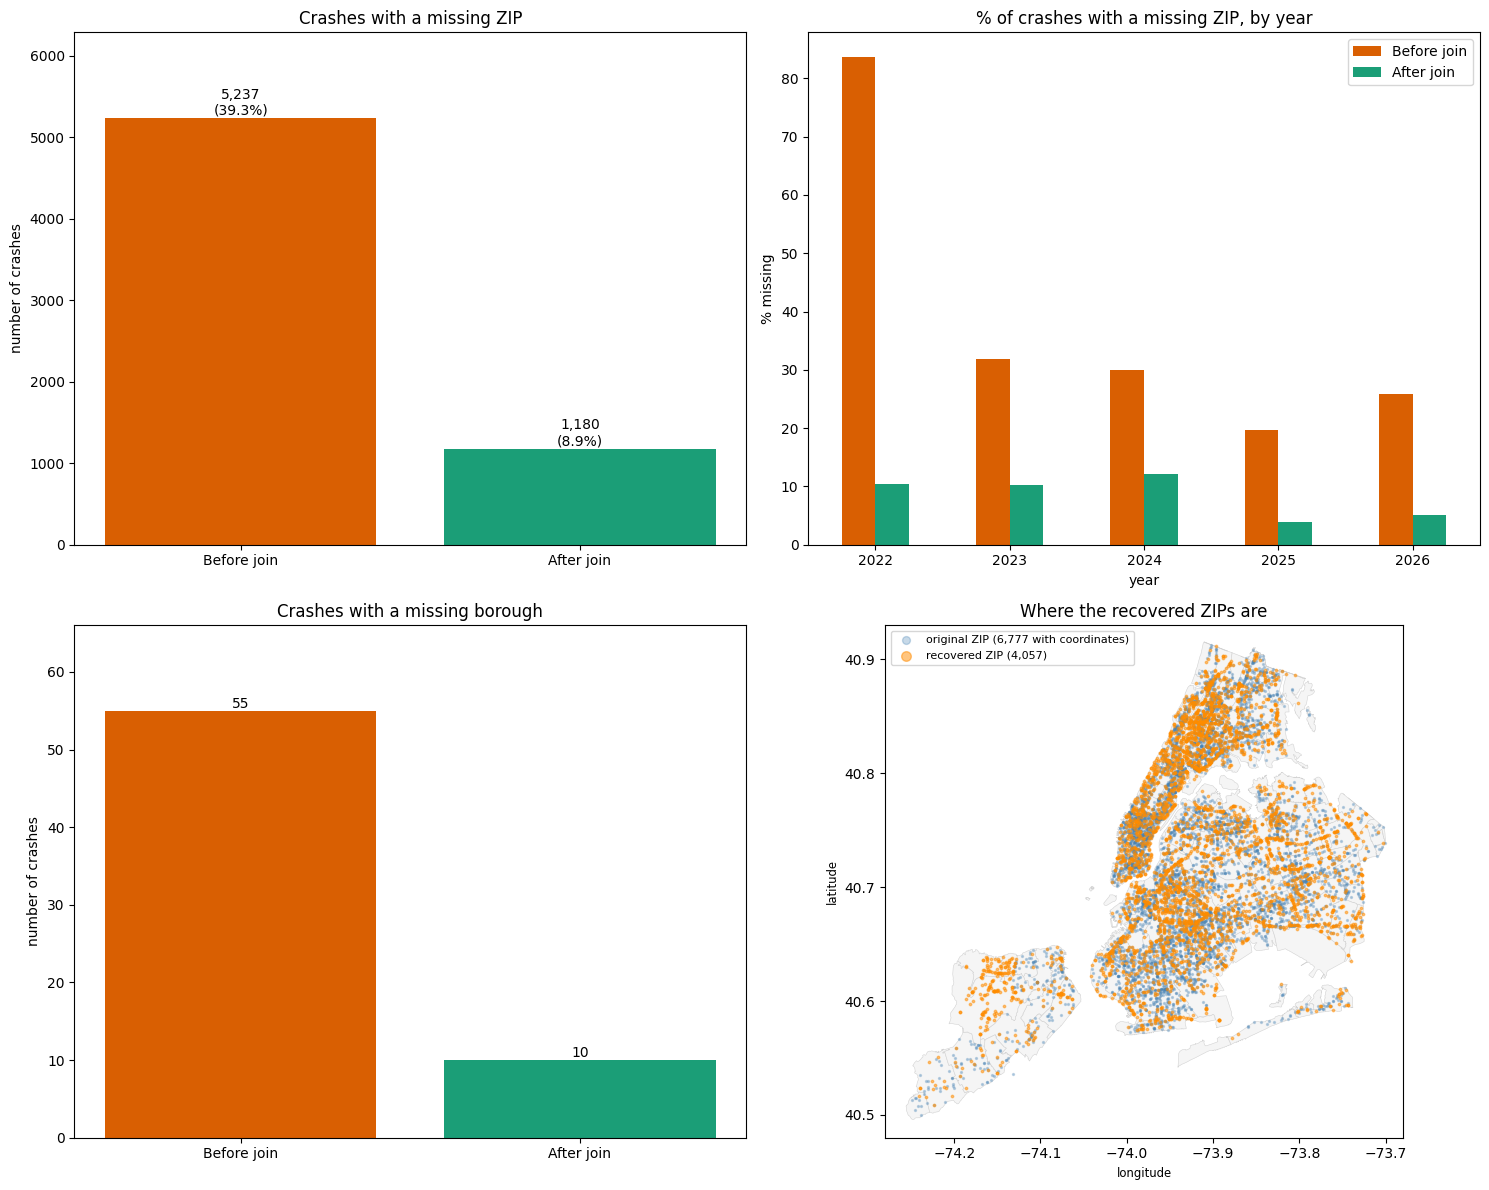

      Before join  After join
year                         
2022         83.7        10.5
2023         31.9        10.3
2024         30.0        12.2
2025         19.7         3.9
2026         25.9         5.1


In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(15, 12))

# 1. Missing ZIPs, before vs after the spatial join
miss = [crash_basic["zip"].isna().sum(), crash_final["zip"].isna().sum()]
bars = ax[0, 0].bar(["Before join", "After join"], miss, color=["#d95f02", "#1b9e77"])
for b, v in zip(bars, miss):
    ax[0, 0].text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(crash_final):.1%})",
                  ha="center", va="bottom")
ax[0, 0].set(title="Crashes with a missing ZIP", ylabel="number of crashes")
ax[0, 0].set_ylim(0, max(miss) * 1.2)

# 2. % missing ZIP by year, before vs after (2022 is the year that needed recovery most)
by_year = pd.DataFrame({
    "Before join": crash_basic["zip"].isna().groupby(crash_basic["year"]).mean() * 100,
    "After join": crash_final["zip"].isna().groupby(crash_final["year"]).mean() * 100,
}).round(1)
by_year.plot.bar(ax=ax[0, 1], color=["#d95f02", "#1b9e77"], rot=0)
ax[0, 1].set(title="% of crashes with a missing ZIP, by year", ylabel="% missing", xlabel="year")

# 3. Missing borough, before vs after
bmiss = [crash_basic["borough"].isna().sum(), crash_final["borough"].isna().sum()]
bars = ax[1, 0].bar(["Before join", "After join"], bmiss, color=["#d95f02", "#1b9e77"])
for b, v in zip(bars, bmiss):
    ax[1, 0].text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom")
ax[1, 0].set(title="Crashes with a missing borough", ylabel="number of crashes")
ax[1, 0].set_ylim(0, max(bmiss) * 1.2)

# 4. Map: original vs recovered locations over the ZIP polygons
zips.plot(ax=ax[1, 1], color="whitesmoke", edgecolor="lightgray", linewidth=0.4)
orig = crash_final[(crash_final["zip_source"] == "original") & crash_final["latitude"].notna()]
rec = crash_final[crash_final["zip_source"] == "spatial_join"]
ax[1, 1].scatter(orig["longitude"], orig["latitude"], s=2, alpha=0.3, color="steelblue",
                 label=f"original ZIP ({len(orig):,} with coordinates)")
ax[1, 1].scatter(rec["longitude"], rec["latitude"], s=3, alpha=0.5, color="darkorange",
                 label=f"recovered ZIP ({len(rec):,})")
ax[1, 1].set(xlim=(-74.28, -73.68), ylim=(40.48, 40.93), xlabel="longitude", ylabel="latitude",
             title="Where the recovered ZIPs are")
ax[1, 1].legend(loc="upper left", markerscale=4, fontsize=8)

plt.tight_layout()
plt.show()

print(by_year)

## 3. Cleaning decisions (following DATA_CONTRACT section 7)

**Empty rows and duplicates.** 444 rows had a null `open_data_crash_id`, `crash_date` and `crash_time` together. They carry no information, so I **dropped** them instead of imputing. One crash id appeared twice and I kept the first occurrence. Result: 13,754 raw rows became 13,309, with 13,309 unique crash ids.

**Dates and times.** `crash_date` had a `T00:00:00.000` suffix and was parsed to a real date, from which I derived `year`, `month`, `year_month` and `crash_weekday`. 656 `crash_time` values had no leading zero (for example `9:30`). They are valid times, so I rewrote them as `HH:MM` and derived `crash_hour` (0 missing). About 227 crashes are at exactly `00:00`, far more than any other time in that hour, so this is probably "time unknown". I **kept** them (some may be real) and added the flag `time_is_midnight`, so charts about the hour of day (Q11) can exclude them.

**ZIP codes.** `zipcode` was renamed `zip` and kept as a 5-digit string. All existing values were already valid. 8,072 crashes (60.7%) had an original ZIP and `zip_source` records where each ZIP comes from.

**Spatial recovery of missing ZIPs.** 5,237 crashes had no ZIP, and 4,057 of them have coordinates. I assigned the ZIP with a spatial join (a point inside a ZIP polygon, GeoPandas `sjoin`) against the shared `nyc_zip_boundaries.geojson` (221 polygons, ZIP field `zcta5`, no CRS declared, so I set EPSG:4326 because the coordinates are longitude/latitude degrees). Original ZIPs were never overwritten. Recovery matters most for 2022: about 84% of 2022 crashes had no ZIP before the join, against 20 to 32% in other years, so without it 2022 would look artificially quiet.

*Validation.* On the 6,768 crashes that have both an original ZIP and coordinates, the spatial ZIP matches the original ZIP in **91.9%** of cases, below the 95% target in the data contract. The disagreements are a **border effect**: the median distance from the crash point to its original ZIP polygon is 2 feet, 89% of the disagreements are within 300 feet, the most common mismatches are neighbouring ZIPs (for example 11206 and 11211), and the agreement is 91.7% to 92.2% in every year. SIRTA places crashes on the street centreline and ZIP boundaries follow streets, so a point can fall on either side. I accepted the recovery with this documented limitation: a recovered ZIP can be the neighbouring ZIP in about 8% of cases.

*Known gaps in the boundary file.* It includes one non-NYC ZIP (07305, Jersey City), but no recovered crash received it (all recovered ZIPs start with 1). Three ZIPs in the crash data have no polygon (10000, 10281, 11251, 48 crashes); they keep their original ZIP. After recovery, **1,180 crashes (8.9%)** still have no ZIP, because they have neither a ZIP nor usable coordinates. They stay missing (`zip_source` = missing) and nothing is guessed.

**Borough.** `crash_borough` was renamed `borough` and standardized to the five contract spellings. 55 crashes had no borough. I filled them through a ZIP-to-borough lookup built from crashes that have both an original ZIP and a borough (the majority borough per ZIP; the boundary file has no borough field). 45 were filled (`borough_source` = spatial_join) and 10 remain missing because they have no ZIP either. Check: for recovered ZIPs, the lookup borough equals the crash's own borough in 99.9% of cases. Two ZIPs appear in more than one borough (border ZIPs), and the majority borough is used.

**Coordinates.** Values outside the NYC bounding box (latitude 40.45 to 40.95, longitude -74.30 to -73.65) would be set to NaN. 0 rows were affected, which matches the scatter plot. The rule stays in the code as a safety net. About 18% of crashes have no coordinates and stay NaN.

**Flags.** `is_highway` is true when `highway_reference_marker` is present (1,052 crashes, 7.9%). I did not infer it from street names, because many parkways are local roads. `is_repeat_location` is true when `similar_fatalities_severe` is at least 1: 817 true, 11,099 false and 1,393 NaN. Missing values stay NaN and are **not** converted to 0, because "unknown" is not the same as "no repeat location".

**Outliers.** See the outlier section above. The IQR rule is degenerate for these count columns (IQR = 0), so I kept all values and used domain rules instead.

## 4. Limitations of the crash data
- SIRTA covers only serious-injury crashes analyzed by NYC DOT, not all crashes.
- Location coverage after recovery differs by year (about 10% of crashes still lack a ZIP in 2022 and 2023, about 12% in 2024 and 4 to 5% in 2025 and 2026), so year-to-year ZIP changes can partly reflect coverage and not real changes in crashes.
- Crashes without a usable location are not random. The team contract reports that about 31% of them involved a fatality, against about 5% of the others, so fatal-share results (Q3) must state how many fatal crashes have no ZIP.
- Recovered ZIPs can be wrong near ZIP borders (about 8% disagreement in the test).
- All findings are associations, not causation.

## 1. Dataset overview

**Dataset:** Serious Injury Response, Tracking & Analysis Program (SIRTA), published by NYC DOT on NYC Open Data. Dataset ID `xeqp-qz8h`.

**Link:** https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h/about_data

**Downloaded:** 5 November 2026 (re-run on 6 November 2026). The source is updated quarterly (last update 9 October 2026), so counts may change slightly on a later download.

| Item | Value |
|---|---|
| Raw rows / columns | 13,754 rows, 23 columns |
| Rows after cleaning | 13,309 (one row per crash) |
| Date range | 2022-01-01 to 2026-06-30 |
| Temporal attributes | `crash_date`, `crash_time` |
| Geographic attributes | `crash_borough`, `zipcode`, `latitude`, `longitude`, `crash_police_precinct`, `community_board`, `council_district`, `census_tract_2020_`, NTA, `on_street`, `cross_street`, `address` |
| Outcomes | `total_severe_injuries`, `total_non_severe_injuries`, `total_fatalities` |
| Other fields used | `highway_reference_marker`, `similar_fatalities_severe` |

**What the data is:** only the serious-injury crashes that NYC DOT analyzed, not all police-reported crashes. Every statement in this project is therefore about serious crashes.

**Why this dataset:** it is a transportation dataset with 23 columns (the brief asks for at least 9), and it carries ZIP, borough, coordinates and exact dates, so it can be joined to the housing filings (H5) by place and time. It is small enough (about 13k rows) to load completely, so **no filtered sample is needed**. I loaded every row with the same paging logic as `src/load_data.py` (the notebook ran in Colab, so I used a copy of that logic and got the same 13,754 rows and 23 columns).

## 2. Known issues found in the raw data

- **444 empty rows:** null `open_data_crash_id`, `crash_date` and `crash_time` together.
- **1 duplicate** crash id.
- **ZIP missing in 39% of crashes** (60.7% present). The gap is uneven: only about 16% of 2022 crashes had an original ZIP, against about 68 to 80% in 2023 to 2026.
- **Coordinates missing in about 18%** of crashes (81.7% of usable rows have them).
- **656 `crash_time` values without a leading zero** (for example `9:30`), and about 227 crashes at exactly `00:00`, far more than any other time in that hour, so probably "time unknown".
- **`highway_reference_marker` is about 92% empty**, as expected, because most crashes are not on highways. `similar_fatalities_severe` is missing in about 10.5% of crashes.
- **Count columns are almost constant** (severe injuries are 1 in most crashes, non-severe injuries and fatalities are 0 in most), which makes the IQR rule uninformative (see the outlier section).

## 3. Integration plan (how crashes are aggregated)

Crashes are individual events, so they are aggregated before joining to housing filings:

- **ZIP by year, 2022 to 2025:** for maps, scatters, ranking and the model. This is the main grain for Q3 and Q4.
- **Borough by year_month, 2022-01 to 2026-06 (54 months):** for seasonality and lag questions.
- **Why not ZIP by month:** SIRTA has too few crashes (about 1 to 2 per ZIP-month), so monthly ZIP counts would be mostly zeros.
- The ZIP-by-year table counts only crashes that have a ZIP (original or recovered). Crashes without a ZIP appear only in the borough-by-month table.

**Limitations:** SIRTA covers serious crashes only; busy areas have more of everything, so all findings are associations, not causation.